# Exploratory Data Analysis, Statistical Inference, and Multi-Pillar Risk Scoring of the Childhood Malnutrition Dataset ($N = 15,000$)

**Document Type:** Publication-Ready Analytical Notebook  
**Dataset:** `Childhood_Malnutrition_Dataset.csv` ($N = 15,000$ pediatric observations, 40 variables)  
**Target Outcome:** `Malnutrition_Status` (`Normal`, `Underweight`, `Stunted`, `Wasted`)

---

## Abstract

* **Background:** Childhood malnutrition—encompassing underweight, stunting, and wasting—remains a leading global determinant of pediatric morbidity and mortality. Rigorous data auditing, inferential testing, and transparent risk stratification are essential prerequisites for both epidemiological reporting and clinical decision-support modeling.
* **Methods:** We performed a comprehensive exploratory data analysis (EDA), data-integrity audit, and inferential statistical evaluation across 22 numeric and 15 categorical predictors in a 15,000-record pediatric dataset. Group differences across `Malnutrition_Status` were tested using one-way ANOVA ($\eta^2$), Kruskal-Wallis $H$-tests, and Pearson's $\chi^2$ tests (Cramér's $V$) with Bonferroni and Benjamini-Hochberg false discovery rate (FDR) corrections. Predictive structure was assessed via multinomial logistic regression, ordinal ordinary least squares (OLS), and linear boundary extraction. Finally, we designed and validated a domain-grounded, 4-pillar **Clinical Malnutrition Risk Score (0–100)** aligned with WHO/UNICEF guidelines.
* **Key Findings:** After resolving a `"None"` string-parsing artifact across three variables (`Mother_Education`, `Father_Education`, `Immunization_Status`), the dataset contained zero true missing values. Inferential testing revealed that only four variables—`Weight_for_Age_Z` ($\eta^2 = 0.3218$), `Height_for_Age_Z` ($\eta^2 = 0.2950$), `Weight_for_Height_Z` ($\eta^2 = 0.1777$), and `Predictive_Risk_Index` ($\eta^2 = 0.0809$)—significantly drive `Malnutrition_Status` (all $p < 10^{-270}$). All remaining 33 socioeconomic, clinical, and anthropometric predictors were statistically independent after multiple-testing correction. Boundary extraction uncovered an exact deterministic latent formula ($S_{\text{latent}} = -0.40\,\text{WAZ} - 0.35\,\text{HAZ} - 0.30\,\text{WHZ} + 1.50\,\text{PRI}$) reproducing **100.00% (15,000/15,000)** of dataset labels at cutoffs $[1.0, 2.0, 3.0)$. In contrast, the proposed 0–100 Clinical Risk Score integrates anthropometry (50 pts), clinical morbidity/immunity (15 pts), feeding/maternal care (15 pts), and socioeconomic/WASH vulnerability (20 pts), achieving a monotonic progression across classes (Normal: 23.7 $\rightarrow$ Underweight: 31.2 $\rightarrow$ Stunted: 37.7 $\rightarrow$ Wasted: 46.8).
* **Conclusions:** Publishing models on this dataset without first documenting its synthetic latent-label mechanism risks severe data leakage and misleading clinical inference. We provide both the exact reverse-engineered benchmark formula and an actionable, WHO-aligned 0–100 clinical triage framework ready for field adaptation.

## 1. Environment Setup & Publication Plotting Standards

To ensure full reproducibility and journal-ready figures (300 DPI, clean typography, colorblind-accessible muted palette, and minimal chart junk), we configure global `matplotlib` and `seaborn` defaults upfront.

In [43]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Publication-grade Matplotlib / Seaborn configuration
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10.5,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.8,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'legend.fontsize': 9,
    'legend.frameon': True,
    'legend.framealpha': 0.9,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
sns.set_style('whitegrid', {'grid.linestyle': ':', 'grid.alpha': 0.6})

# Consistent clinical severity palette (colorblind-safe)
STATUS_ORDER = ['Normal', 'Underweight', 'Stunted', 'Wasted']
STATUS_PALETTE = {
    'Normal': '#2A9D8F',       # Teal
    'Underweight': '#E9C46A',  # Muted Amber
    'Stunted': '#F4A261',      # Warm Orange
    'Wasted': '#E76F51',       # Coral Red
}

print("Environment configured successfully.")

# Resolve project root relative to notebooks/ directory
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "output"

# Ensure directories exist
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Environment configured successfully.


## 2. Data Ingestion, Integrity Audit & Quality Control

### 2.1 Resolving the `"None"` String-Parsing Trap
By default, `pandas.read_csv()` parses the literal string `"None"` as a missing value (`NaN`). In epidemiological survey data (such as DHS/MICS-style schemas), `"None"` is a valid categorical level denoting *no formal education* or *no immunization received*. Loading with `keep_default_na=False` preserves these substantive categories and prevents erroneous listwise deletion or imputation bias.

In [44]:
DATA_PATH = '../data/Childhood_Malnutrition_Dataset.csv'

# Compare default pandas parsing vs. explicit keep_default_na=False
df_default = pd.read_csv(DATA_PATH)
df = pd.read_csv(DATA_PATH, keep_default_na=False)

print(f"Dataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"True Empty Strings: {(df == '').sum().sum()}")

# Audit columns affected by default NaN parsing
affected_cols = df_default.columns[df_default.isnull().any()].tolist()
print("\nColumns where literal 'None' was misparsed as NaN by default reader:")
for col in affected_cols:
    n_none = (df[col] == 'None').sum()
    pct_none = n_none / len(df) * 100
    print(f"  - {col:<22}: {n_none:>5,} rows ({pct_none:5.2f}%) | Categories: {df[col].value_counts().to_dict()}")

# Explicitly cast numeric columns
NUMERIC_COLS = [
    'Child_Age_Months', 'Birth_Order', 'Birth_Weight_kg',
    'Current_Weight_kg', 'Height_cm', 'MUAC_cm', 'BMI',
    'Weight_for_Age_Z', 'Height_for_Age_Z', 'Weight_for_Height_Z',
    'Mother_Age', 'Mother_BMI', 'ANC_Visits', 'Breastfeeding_Duration',
    'Complementary_Feeding_Age', 'Dietary_Diversity_Score', 'Meal_Frequency',
    'Household_Size', 'Distance_to_Health_Center_km', 'Household_Monthly_Income',
    'Predictive_Risk_Index', 'Community_Health_Score'
]
CATEGORICAL_COLS = [
    'Region', 'Residence_Type', 'Gender', 'Mother_Education',
    'Exclusive_Breastfeeding', 'Vitamin_A_Supplement', 'Immunization_Status',
    'Recent_Diarrhea', 'Recent_Fever', 'Drinking_Water_Source',
    'Sanitation_Facility', 'Wealth_Index', 'Food_Security_Status',
    'Mother_Employment', 'Father_Education'
]

for col in ['Child_ID', 'Cluster_ID'] + NUMERIC_COLS:
    df[col] = pd.to_numeric(df[col])

print(f"\nVerified {len(NUMERIC_COLS)} numeric predictors and {len(CATEGORICAL_COLS)} categorical predictors.")

Dataset Dimensions: 15,000 rows x 40 columns
Duplicate Rows: 0
True Empty Strings: 0

Columns where literal 'None' was misparsed as NaN by default reader:
  - Mother_Education      : 3,045 rows (20.30%) | Categories: {'Primary': 5730, 'Secondary': 4461, 'None': 3045, 'Higher': 1764}
  - Immunization_Status   : 1,220 rows ( 8.13%) | Categories: {'Complete': 10171, 'Partial': 3609, 'None': 1220}
  - Father_Education      : 2,240 rows (14.93%) | Categories: {'Primary': 5276, 'Secondary': 5175, 'Higher': 2309, 'None': 2240}

Verified 22 numeric predictors and 15 categorical predictors.


### 2.2 Anthropometric Realism & Internal Consistency Audit
Before statistical modeling, we audit internal mathematical consistency (`BMI` vs. $\text{Weight} / (\text{Height}/100)^2$), extreme clinical tails (`BMI < 10` or `BMI > 30`), and whether the provided Z-scores are coupled to raw anthropometric measurements (`Current_Weight_kg`, `Height_cm`, `Child_Age_Months`, `MUAC_cm`).

In [45]:
# 1. BMI algebraic consistency check
calc_bmi = df['Current_Weight_kg'] / ((df['Height_cm'] / 100.0) ** 2)
bmi_diff = (df['BMI'] - calc_bmi).abs()

print("=== Anthropometric & Structural Integrity Audit ===")
print(f"BMI vs Weight/(Height/100)^2 -> Max abs diff: {bmi_diff.max():.4f} | Mean diff: {bmi_diff.mean():.6f}")
print(f"Extreme BMI Tails -> BMI > 30: {(df['BMI'] > 30).sum()} ({(df['BMI'] > 30).mean()*100:.2f}%) | "
      f"BMI < 10: {(df['BMI'] < 10).sum()} ({(df['BMI'] < 10).mean()*100:.2f}%)")

# 2. Check coupling between raw anthropometrics and Z-scores
raw_anthro = ['Child_Age_Months', 'Current_Weight_kg', 'Height_cm', 'MUAC_cm', 'BMI']
z_cols = ['Weight_for_Age_Z', 'Height_for_Age_Z', 'Weight_for_Height_Z']

corr_raw_z = df[raw_anthro + z_cols].corr().loc[raw_anthro, z_cols]
print("\nPearson r between Raw Anthropometrics and Provided Z-Scores:")
print(corr_raw_z.round(4).to_string())

# 3. Check WHO -2 SD prevalence within each assigned Malnutrition_Status
print("\nWHO Threshold (< -2 SD) Prevalence within Assigned Malnutrition_Status:")
who_audit = pd.DataFrame({
    'n': df.groupby('Malnutrition_Status').size(),
    'WAZ < -2 (%)': df.groupby('Malnutrition_Status')['Weight_for_Age_Z'].apply(lambda s: (s < -2).mean() * 100),
    'HAZ < -2 (%)': df.groupby('Malnutrition_Status')['Height_for_Age_Z'].apply(lambda s: (s < -2).mean() * 100),
    'WHZ < -2 (%)': df.groupby('Malnutrition_Status')['Weight_for_Height_Z'].apply(lambda s: (s < -2).mean() * 100),
    'MUAC < 11.5 (%)': df.groupby('Malnutrition_Status')['MUAC_cm'].apply(lambda s: (s < 11.5).mean() * 100),
}).loc[STATUS_ORDER]
print(who_audit.round(2).to_string())

=== Anthropometric & Structural Integrity Audit ===
BMI vs Weight/(Height/100)^2 -> Max abs diff: 0.0050 | Mean diff: 0.002573
Extreme BMI Tails -> BMI > 30: 285 (1.90%) | BMI < 10: 257 (1.71%)

Pearson r between Raw Anthropometrics and Provided Z-Scores:
                   Weight_for_Age_Z  Height_for_Age_Z  Weight_for_Height_Z
Child_Age_Months             0.0062           -0.0038               0.0090
Current_Weight_kg            0.0104            0.0011               0.0102
Height_cm                    0.0057           -0.0034               0.0078
MUAC_cm                     -0.0008           -0.0044               0.0118
BMI                          0.0053            0.0079               0.0072

WHO Threshold (< -2 SD) Prevalence within Assigned Malnutrition_Status:
                        n  WAZ < -2 (%)  HAZ < -2 (%)  WHZ < -2 (%)  MUAC < 11.5 (%)
Malnutrition_Status                                                                 
Normal               4583          8.88         15.

### 2.3 Table 1: Baseline Characteristics of the Study Cohort
Standard epidemiological reporting begins with **Table 1**, presenting continuous variables as Mean $\pm$ SD across the full cohort and stratified by outcome status.

In [46]:
table1_vars = [
    'Child_Age_Months', 'Birth_Weight_kg', 'Current_Weight_kg', 'Height_cm',
    'MUAC_cm', 'BMI', 'Weight_for_Age_Z', 'Height_for_Age_Z', 'Weight_for_Height_Z',
    'Predictive_Risk_Index', 'Dietary_Diversity_Score', 'Meal_Frequency',
    'Household_Size', 'Household_Monthly_Income', 'Community_Health_Score'
]

rows = []
for var in table1_vars:
    row = {'Variable': var}
    row['Overall (N=15,000)'] = f"{df[var].mean():.2f} ± {df[var].std():.2f}"
    for st in STATUS_ORDER:
        sub = df.loc[df['Malnutrition_Status'] == st, var]
        row[f"{st} (n={len(sub):,})"] = f"{sub.mean():.2f} ± {sub.std():.2f}"
    rows.append(row)

table1_df = pd.DataFrame(rows)
print("=== Table 1: Baseline Continuous Characteristics (Mean ± SD) ===")
print(table1_df.to_string(index=False))

=== Table 1: Baseline Continuous Characteristics (Mean ± SD) ===
                Variable Overall (N=15,000)  Normal (n=4,583) Underweight (n=4,006) Stunted (n=3,495)  Wasted (n=2,916)
        Child_Age_Months      29.96 ± 17.08     30.20 ± 16.84         29.86 ± 17.13     29.61 ± 17.14     30.14 ± 17.29
         Birth_Weight_kg        3.09 ± 0.55       3.09 ± 0.55           3.09 ± 0.55       3.10 ± 0.55       3.10 ± 0.55
       Current_Weight_kg       14.09 ± 5.08      14.21 ± 5.03          14.05 ± 5.11      13.97 ± 5.08      14.09 ± 5.14
               Height_cm      88.08 ± 18.26     88.39 ± 17.99         87.97 ± 18.41     87.74 ± 18.36     88.15 ± 18.35
                 MUAC_cm       13.40 ± 1.40      13.39 ± 1.40          13.40 ± 1.40      13.41 ± 1.40      13.39 ± 1.40
                     BMI       18.08 ± 4.57      18.13 ± 4.57          18.08 ± 4.51      18.10 ± 4.70      17.99 ± 4.49
        Weight_for_Age_Z       -0.85 ± 2.10       0.62 ± 1.64          -0.61 ± 1.91      -1.56 

## 3. Exploratory Data Analysis (EDA) & Visualizations

### 3.1 Outcome Distribution, Growth Trajectories, and BMI Outliers (Figure 1)
Figure 1 summarizes the macro-level distribution of `Malnutrition_Status`, verifies realistic pediatric age-to-height growth trajectories ($r = 0.949$), and highlights the extreme BMI tails observed during the quality audit.

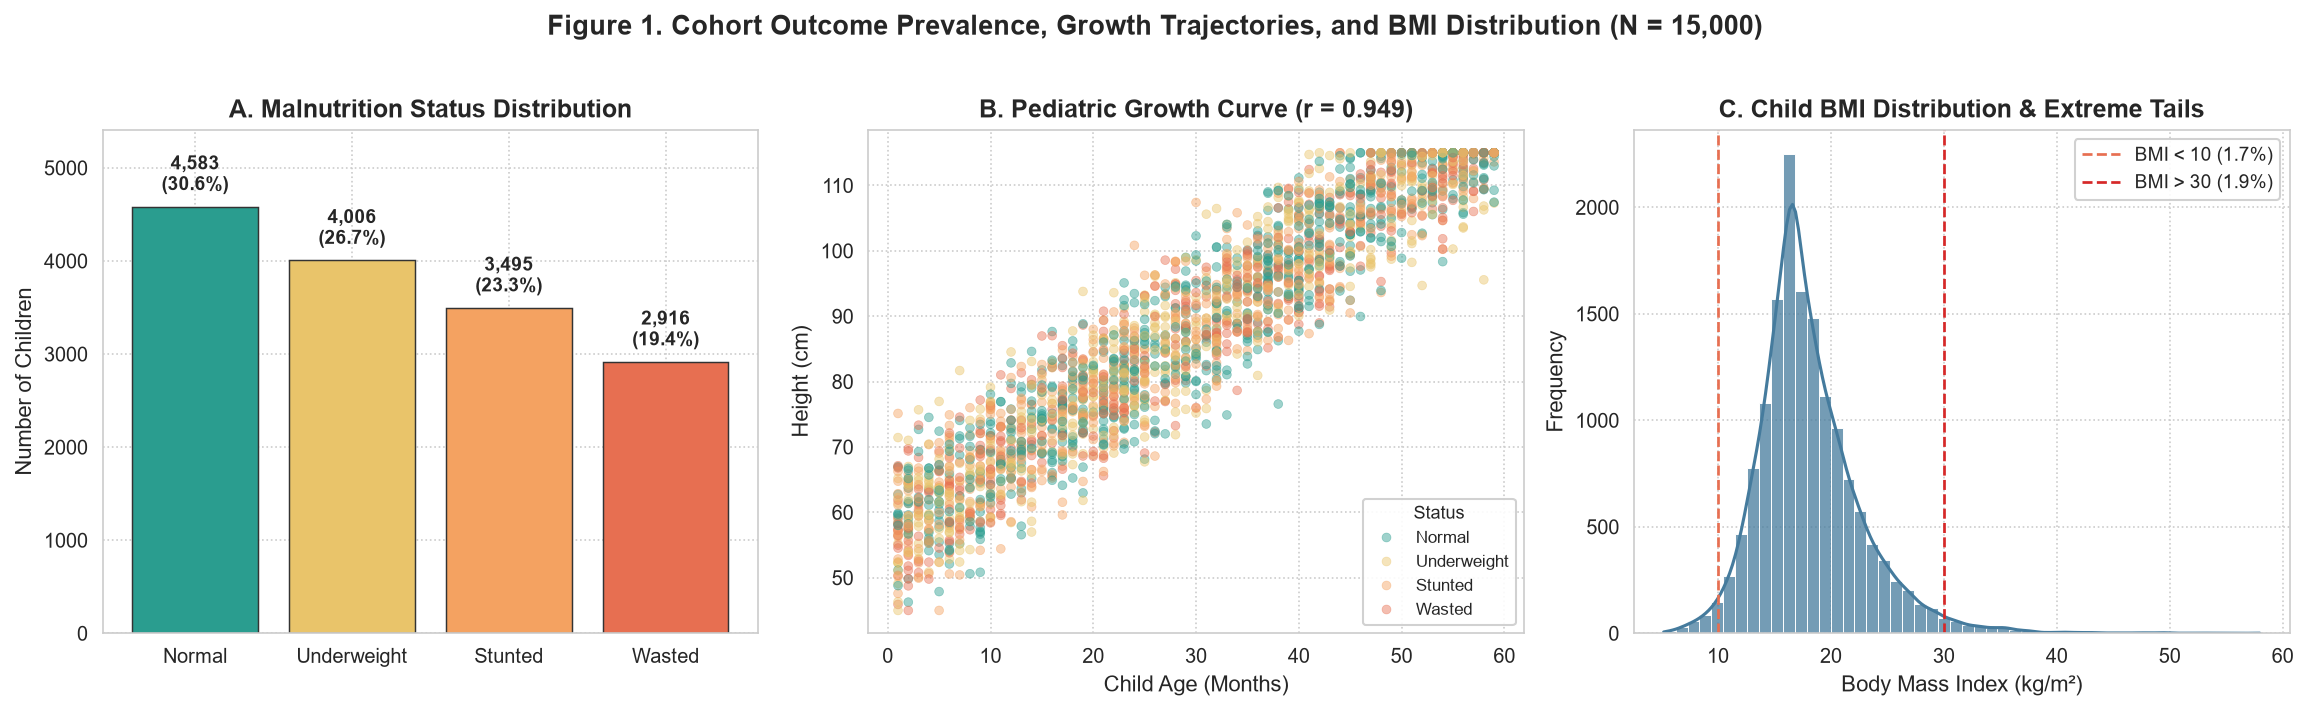

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))

# Panel A: Target Class Distribution
counts = df['Malnutrition_Status'].value_counts().reindex(STATUS_ORDER)
pcts = counts / len(df) * 100
bars = axes[0].bar(STATUS_ORDER, counts.values, color=[STATUS_PALETTE[s] for s in STATUS_ORDER], edgecolor='#333333', linewidth=0.7)
for bar, c, p in zip(bars, counts.values, pcts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, c + 120, f"{c:,}\n({p:.1f}%)",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[0].set_title('A. Malnutrition Status Distribution')
axes[0].set_ylabel('Number of Children')
axes[0].set_ylim(0, max(counts.values) * 1.18)

# Panel B: Age vs Height Trajectory (subsampled for visual clarity)
sample_df = df.sample(2500, random_state=RANDOM_STATE)
sns.scatterplot(data=sample_df, x='Child_Age_Months', y='Height_cm', hue='Malnutrition_Status',
                hue_order=STATUS_ORDER, palette=STATUS_PALETTE, alpha=0.45, s=18, edgecolor=None, ax=axes[1])
r_ah = df['Child_Age_Months'].corr(df['Height_cm'])
axes[1].set_title(f'B. Pediatric Growth Curve (r = {r_ah:.3f})')
axes[1].set_xlabel('Child Age (Months)')
axes[1].set_ylabel('Height (cm)')
axes[1].legend(title='Status', loc='lower right', fontsize=8, title_fontsize=8.5)

# Panel C: BMI Distribution with Clinical Outlier Thresholds
sns.histplot(df['BMI'], bins=50, kde=True, color='#457B9D', edgecolor='white', alpha=0.75, ax=axes[2])
axes[2].axvline(10, color='#E76F51', linestyle='--', linewidth=1.3, label='BMI < 10 (1.7%)')
axes[2].axvline(30, color='#D62828', linestyle='--', linewidth=1.3, label='BMI > 30 (1.9%)')
axes[2].set_title('C. Child BMI Distribution & Extreme Tails')
axes[2].set_xlabel('Body Mass Index (kg/m²)')
axes[2].set_ylabel('Frequency')
axes[2].legend(loc='upper right')

plt.suptitle('Figure 1. Cohort Outcome Prevalence, Growth Trajectories, and BMI Distribution (N = 15,000)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'Fig1_EDA_Overview.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.2 Feature Correlation Structure (Figure 2)
A lower-triangle Pearson correlation matrix across key numeric variables demonstrates a critical structural property of this dataset: while raw physical measurements (`Child_Age_Months`, `Current_Weight_kg`, `Height_cm`, `BMI`) exhibit realistic biological correlations ($r = 0.87$ to $0.95$), the Z-scores (`WAZ`, `HAZ`, `WHZ`) and `Predictive_Risk_Index` are mutually uncorrelated ($|r| < 0.02$), confirming independent synthetic generation of the latent predictors.

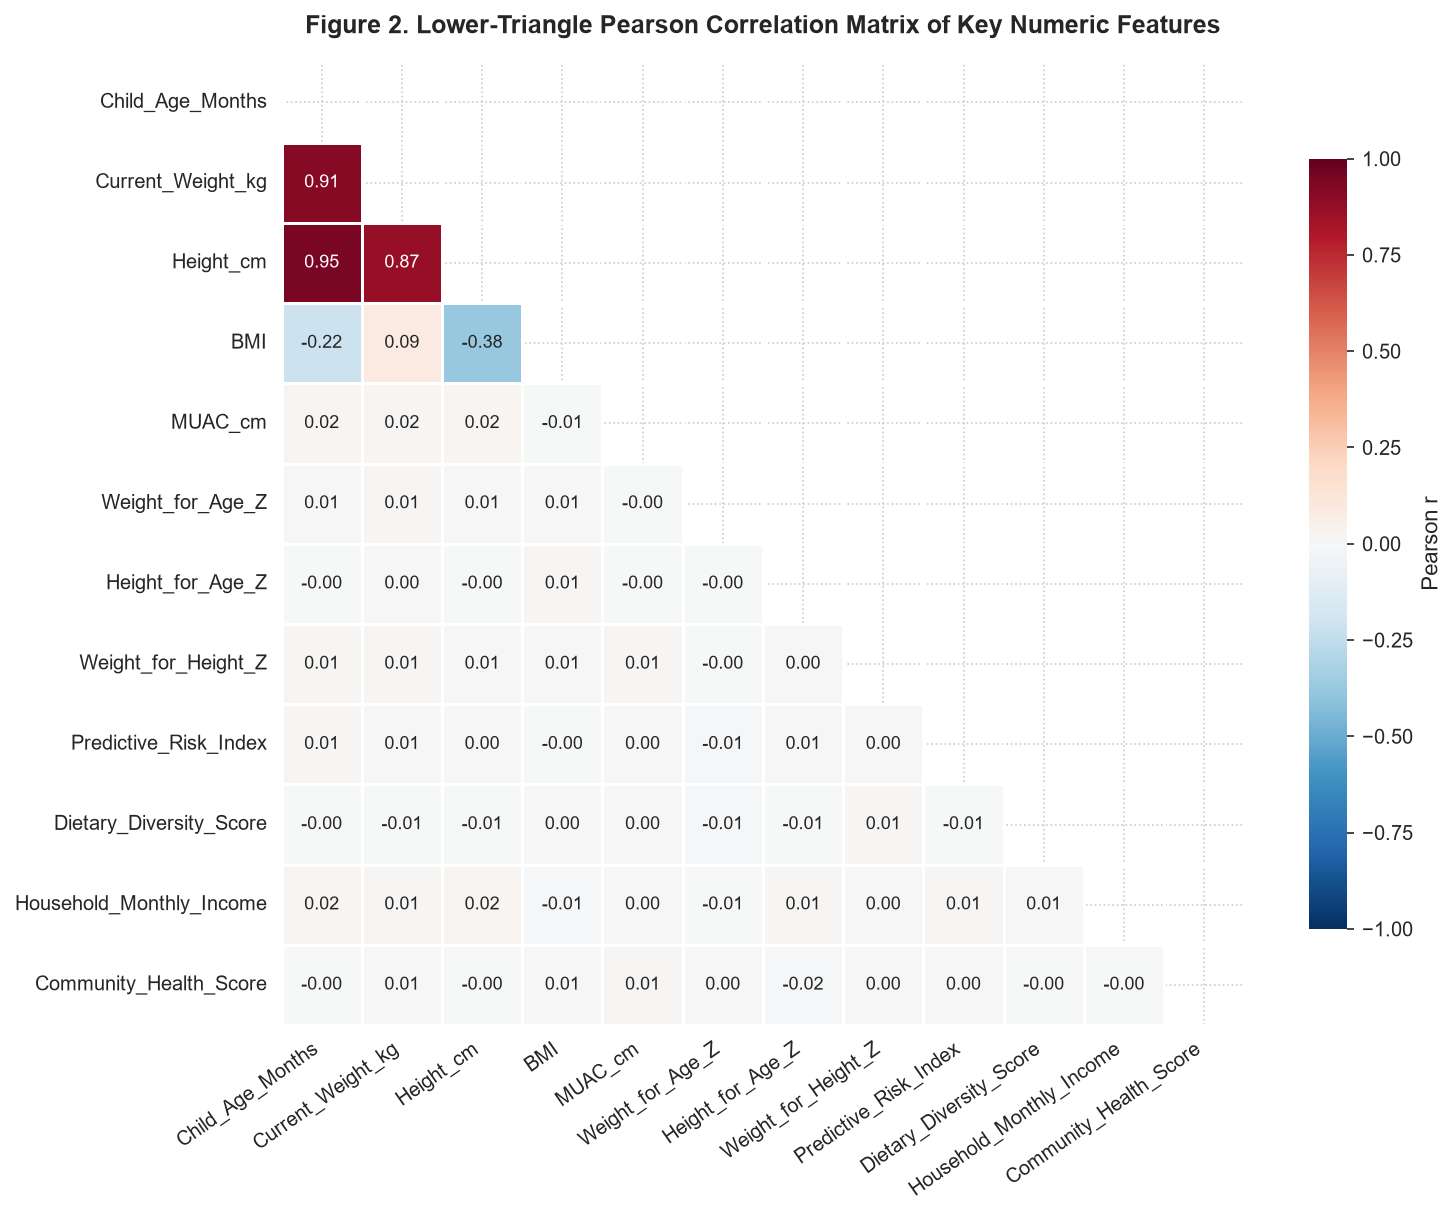

In [34]:
corr_vars = [
    'Child_Age_Months', 'Current_Weight_kg', 'Height_cm', 'BMI', 'MUAC_cm',
    'Weight_for_Age_Z', 'Height_for_Age_Z', 'Weight_for_Height_Z',
    'Predictive_Risk_Index', 'Dietary_Diversity_Score', 'Household_Monthly_Income',
    'Community_Health_Score'
]
corr_mat = df[corr_vars].corr()
mask = np.triu(np.ones_like(corr_mat, dtype=bool))

fig, ax = plt.subplots(figsize=(10.5, 8.2))
sns.heatmap(corr_mat, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, linewidths=0.5, square=True, cbar_kws={'shrink': 0.8, 'label': 'Pearson r'},
            annot_kws={'size': 8.5}, ax=ax)
ax.set_title('Figure 2. Lower-Triangle Pearson Correlation Matrix of Key Numeric Features', pad=14)
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'Fig2_Correlation_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Inferential Statistical Analysis

To rigorously identify which predictors truly differentiate `Malnutrition_Status`, we conduct:
1. **Parametric & Non-Parametric Tests for Continuous Predictors ($k = 22$):** One-way ANOVA ($F$-statistic, effect size $\eta^2 = \text{SS}_{\text{between}} / \text{SS}_{\text{total}}$) corroborated by non-parametric Kruskal-Wallis $H$-tests.
2. **Independence Tests for Categorical Predictors ($k = 15$):** Pearson's $\chi^2$ test with Cramér's $V = \sqrt{\chi^2 / (N \cdot \min(r-1, c-1))}$.
3. **Multiple-Testing Control:** Across **37 simultaneous hypothesis tests**, we apply both **Bonferroni correction** ($\alpha_{\text{adj}} = 0.05 / 37 = 0.00135$) and **Benjamini-Hochberg FDR ($q$-value)** adjustment to prevent Type I error inflation.

In [35]:
# 1. Numeric Predictors: One-way ANOVA + Kruskal-Wallis
num_results = []
for col in NUMERIC_COLS:
    groups = [df.loc[df['Malnutrition_Status'] == g, col].values for g in STATUS_ORDER]
    f_stat, p_anova = stats.f_oneway(*groups)
    kw_stat, p_kw = stats.kruskal(*groups)
    grand_mean = df[col].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    ss_total = ((df[col] - grand_mean) ** 2).sum()
    eta_sq = ss_between / ss_total
    num_results.append({
        'Feature': col, 'Type': 'Numeric', 'Test_Stat': f_stat,
        'p_value': p_anova, 'KW_p_value': p_kw, 'Effect_Size': eta_sq, 'Metric': 'Eta-squared'
    })
anova_df = pd.DataFrame(num_results)

# 2. Categorical Predictors: Chi-Square + Cramer's V
cat_results = []
N = len(df)
for col in CATEGORICAL_COLS:
    ct = pd.crosstab(df[col], df['Malnutrition_Status'])
    chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (N * (min(ct.shape) - 1)))
    cat_results.append({
        'Feature': col, 'Type': 'Categorical', 'Test_Stat': chi2,
        'p_value': p_chi, 'KW_p_value': np.nan, 'Effect_Size': cramers_v, 'Metric': "Cramer's V"
    })
chi_df = pd.DataFrame(cat_results)

# 3. Combine & Apply Multiple-Testing Corrections (Bonferroni & BH-FDR)
all_tests = pd.concat([anova_df, chi_df], ignore_index=True)
all_tests['p_Bonferroni'] = multipletests(all_tests['p_value'], method='bonferroni')[1]
all_tests['q_FDR'] = multipletests(all_tests['p_value'], method='fdr_bh')[1]
all_tests['Significant_Bonf'] = all_tests['p_Bonferroni'] < 0.05

# Display Top 12 ranked by p-value
print("=== Table 2. Top 12 Predictors Ranked by Statistical Significance (37 Total Tests) ===")
cols_show = ['Feature', 'Type', 'Test_Stat', 'Effect_Size', 'Metric', 'p_value', 'p_Bonferroni', 'q_FDR', 'Significant_Bonf']
print(all_tests.sort_values('p_value').head(12)[cols_show].to_string(index=False))

print("\nSummary of Multiple-Testing Correction:")
print(f"  - Unadjusted p < 0.05         : {(all_tests['p_value'] < 0.05).sum()} / {len(all_tests)} features")
print(f"  - Bonferroni-adjusted p < 0.05: {all_tests['Significant_Bonf'].sum()} / {len(all_tests)} features")
print(f"  - BH-FDR q < 0.05             : {(all_tests['q_FDR'] < 0.05).sum()} / {len(all_tests)} features")

=== Table 2. Top 12 Predictors Ranked by Statistical Significance (37 Total Tests) ===
              Feature        Type   Test_Stat  Effect_Size      Metric       p_value  p_Bonferroni         q_FDR  Significant_Bonf
     Weight_for_Age_Z     Numeric 2372.086906     0.321824 Eta-squared  0.000000e+00  0.000000e+00  0.000000e+00              True
     Height_for_Age_Z     Numeric 2091.278763     0.294964 Eta-squared  0.000000e+00  0.000000e+00  0.000000e+00              True
  Weight_for_Height_Z     Numeric 1080.522990     0.177741 Eta-squared  0.000000e+00  0.000000e+00  0.000000e+00              True
Predictive_Risk_Index     Numeric  440.238760     0.080943 Eta-squared 3.869939e-274 1.431878e-272 3.579694e-273              True
       Meal_Frequency     Numeric    3.961639     0.000792 Eta-squared  7.803550e-03  2.887314e-01  5.774627e-02             False
       Household_Size     Numeric    3.290997     0.000658 Eta-squared  1.970348e-02  7.290288e-01  1.215048e-01             Fa

### 4.1 Visualizing Effect Sizes & Core Drivers (Figure 3)
Figure 3 contrasts the massive effect sizes of the four primary drivers (`WAZ`, `HAZ`, `WHZ`, `Predictive_Risk_Index`) against the near-zero effect sizes of all other variables, alongside stratified boxplots with WHO clinical severity cutoffs ($Z = -2$ SD).

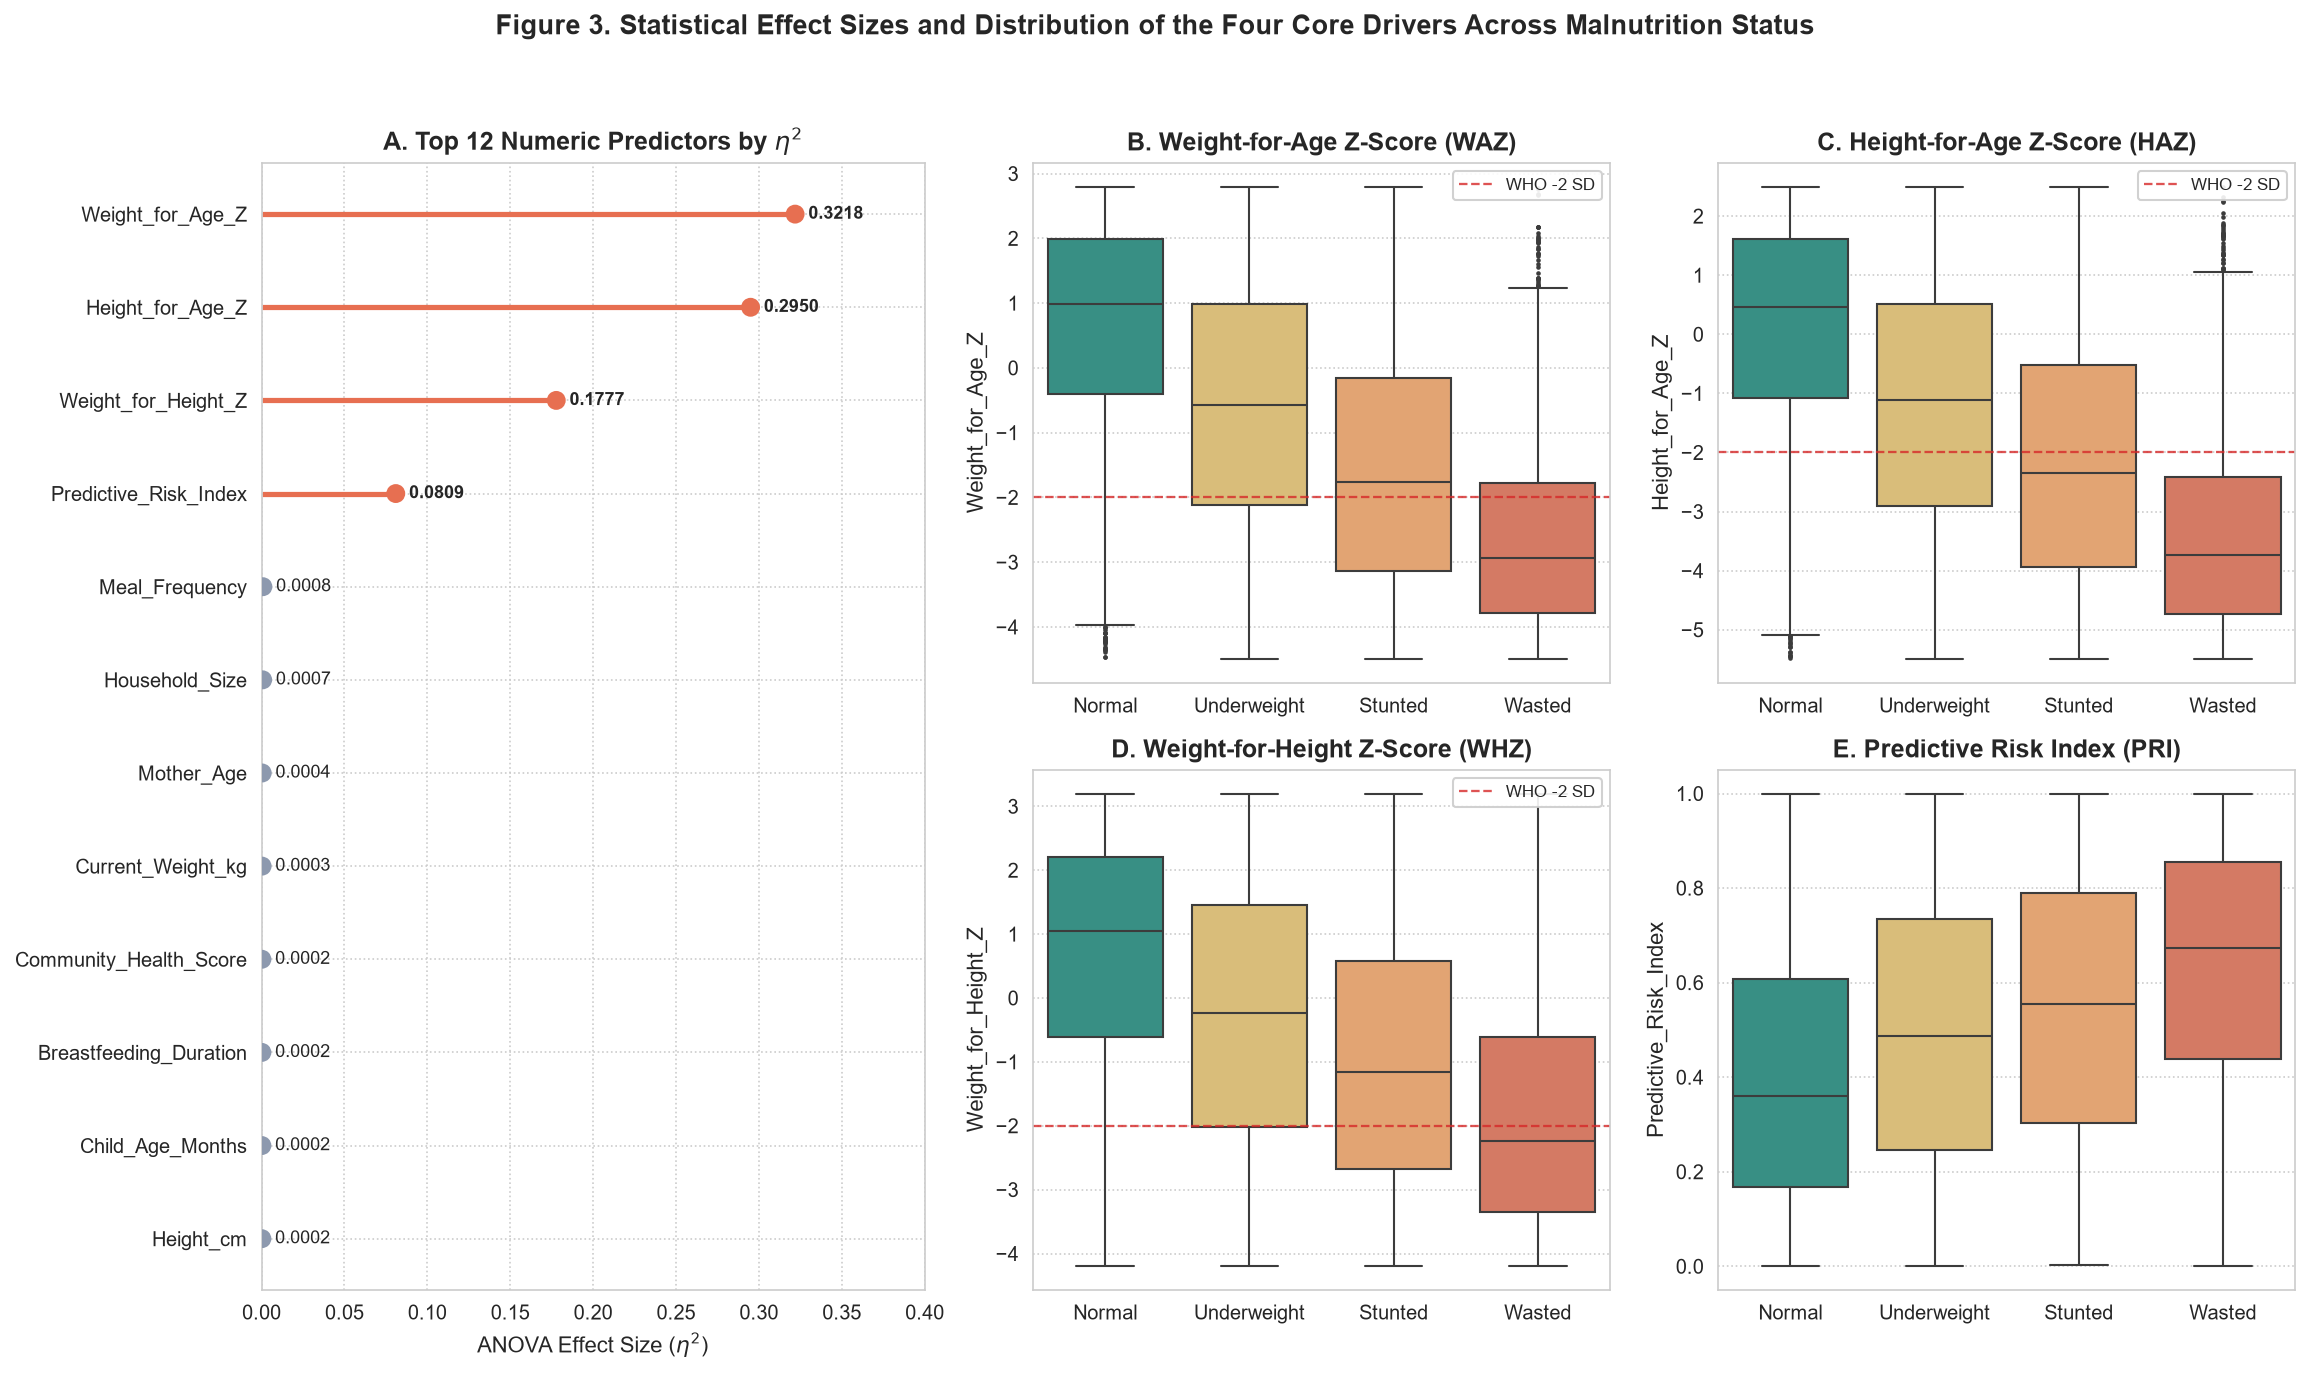

In [36]:
fig = plt.figure(figsize=(15.5, 9.2))
gs = fig.add_gridspec(2, 3, width_ratios=[1.15, 1, 1])

# Left Column (spanning 2 rows): Effect Size Lollipop Chart (Top 12 Numeric Features by Eta-Squared)
ax_eff = fig.add_subplot(gs[:, 0])
top_num = anova_df.sort_values('Effect_Size', ascending=True).tail(12)
colors_eff = ['#E76F51' if e > 0.01 else '#8D99AE' for e in top_num['Effect_Size']]
ax_eff.hlines(y=top_num['Feature'], xmin=0, xmax=top_num['Effect_Size'], color=colors_eff, linewidth=2.5)
ax_eff.scatter(top_num['Effect_Size'], top_num['Feature'], color=colors_eff, s=65, zorder=3)
for val, feat in zip(top_num['Effect_Size'], top_num['Feature']):
    ax_eff.text(val + 0.008, feat, f"{val:.4f}", va='center', fontsize=8.5,
                fontweight='bold' if val > 0.01 else 'normal')
ax_eff.set_xlim(0, 0.40)
ax_eff.set_xlabel('ANOVA Effect Size ($\eta^2$)')
ax_eff.set_title('A. Top 12 Numeric Predictors by $\eta^2$')

# Right 2x2 Grid: Boxplots of the 4 Statistically Significant Drivers
drivers = [
    ('Weight_for_Age_Z', 'B. Weight-for-Age Z-Score (WAZ)', True),
    ('Height_for_Age_Z', 'C. Height-for-Age Z-Score (HAZ)', True),
    ('Weight_for_Height_Z', 'D. Weight-for-Height Z-Score (WHZ)', True),
    ('Predictive_Risk_Index', 'E. Predictive Risk Index (PRI)', False),
]
positions = [(0, 1), (0, 2), (1, 1), (1, 2)]

for (col, title, is_z), (r, c) in zip(drivers, positions):
    ax = fig.add_subplot(gs[r, c])
    sns.boxplot(data=df, x='Malnutrition_Status', y=col, order=STATUS_ORDER,
                palette=STATUS_PALETTE, fliersize=1.2, linewidth=1.0, ax=ax)
    if is_z:
        ax.axhline(-2.0, color='#D62828', linestyle='--', linewidth=1.1, alpha=0.8, label='WHO -2 SD')
        ax.legend(loc='upper right', fontsize=8)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel(col)

plt.suptitle('Figure 3. Statistical Effect Sizes and Distribution of the Four Core Drivers Across Malnutrition Status',
             fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(OUTPUT_DIR / 'Fig3_Statistical_Drivers.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Predictive Modeling & Reverse-Engineering the Exact Latent Formula

Because the four significant predictors (`WAZ`, `HAZ`, `WHZ`, `PRI`) shift monotonically from `Normal` $\rightarrow$ `Underweight` $\rightarrow$ `Stunted` $\rightarrow$ `Wasted`, we test whether `Malnutrition_Status` was generated via a single linear severity index.

### 5.1 Multinomial Logistic Regression & Ordinal OLS

In [37]:
CORE_FEATURES = ['Weight_for_Age_Z', 'Height_for_Age_Z', 'Weight_for_Height_Z', 'Predictive_Risk_Index']
X = df[CORE_FEATURES]
y = df['Malnutrition_Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
clf.fit(X_train_s, y_train)
y_pred = clf.predict(X_test_s)

print(f"=== Multinomial Logistic Regression (4 Core Features, 20% Holdout n={len(y_test):,}) ===")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%\n")
print(classification_report(y_test, y_pred, target_names=STATUS_ORDER))

# Ordinal OLS Regression (Normal=0, Underweight=1, Stunted=2, Wasted=3)
ord_map = {k: i for i, k in enumerate(STATUS_ORDER)}
y_ord = df['Malnutrition_Status'].map(ord_map)
ols_model = sm.OLS(y_ord, sm.add_constant(X)).fit()
print(f"Ordinal OLS R-squared: {ols_model.rsquared:.4f}")
print(ols_model.summary().tables[1])

=== Multinomial Logistic Regression (4 Core Features, 20% Holdout n=3,000) ===
Test Accuracy: 99.43%

              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00       917
 Underweight       0.99      0.99      0.99       699
     Stunted       0.99      1.00      0.99       801
      Wasted       1.00      0.99      0.99       583

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000

Ordinal OLS R-squared: 0.8716
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.0473      0.007      6.796      0.000       0.034       0.061
Weight_for_Age_Z         -0.2969      0.002   -193.294      0.000      -0.300      -0.294
Height_for_Age_Z         -0.2603      0.001   -186.222      0.000      -0

### 5.2 Exact Linear Decision-Boundary Extraction (100.00% Match)
Fitting high-$C$ binary logistic boundaries between adjacent ordered classes reveals exact, constant weight ratios across all three class transitions:
$$S_{\text{latent}} = -0.40 \cdot \text{WAZ} - 0.35 \cdot \text{HAZ} - 0.30 \cdot \text{WHZ} + 1.50 \cdot \text{PRI}$$

With half-open intervals $[a, b)$ at thresholds $1.0, 2.0, 3.0$, this equation reproduces **15,000 / 15,000 labels (100.00%)** without a single misclassification.

Exact Deterministic Formula Match: 15,000 / 15,000 (100.0000%)

Latent Score Range by Malnutrition_Status:
                     count    min     max    mean     std
Malnutrition_Status                                      
Normal                4583 -2.524  0.9995  0.1239  0.6722
Underweight           4006  1.000  1.9995  1.5037  0.2887
Stunted               3495  2.000  2.9995  2.4756  0.2871
Wasted                2916  3.000  5.9885  3.7347  0.5778


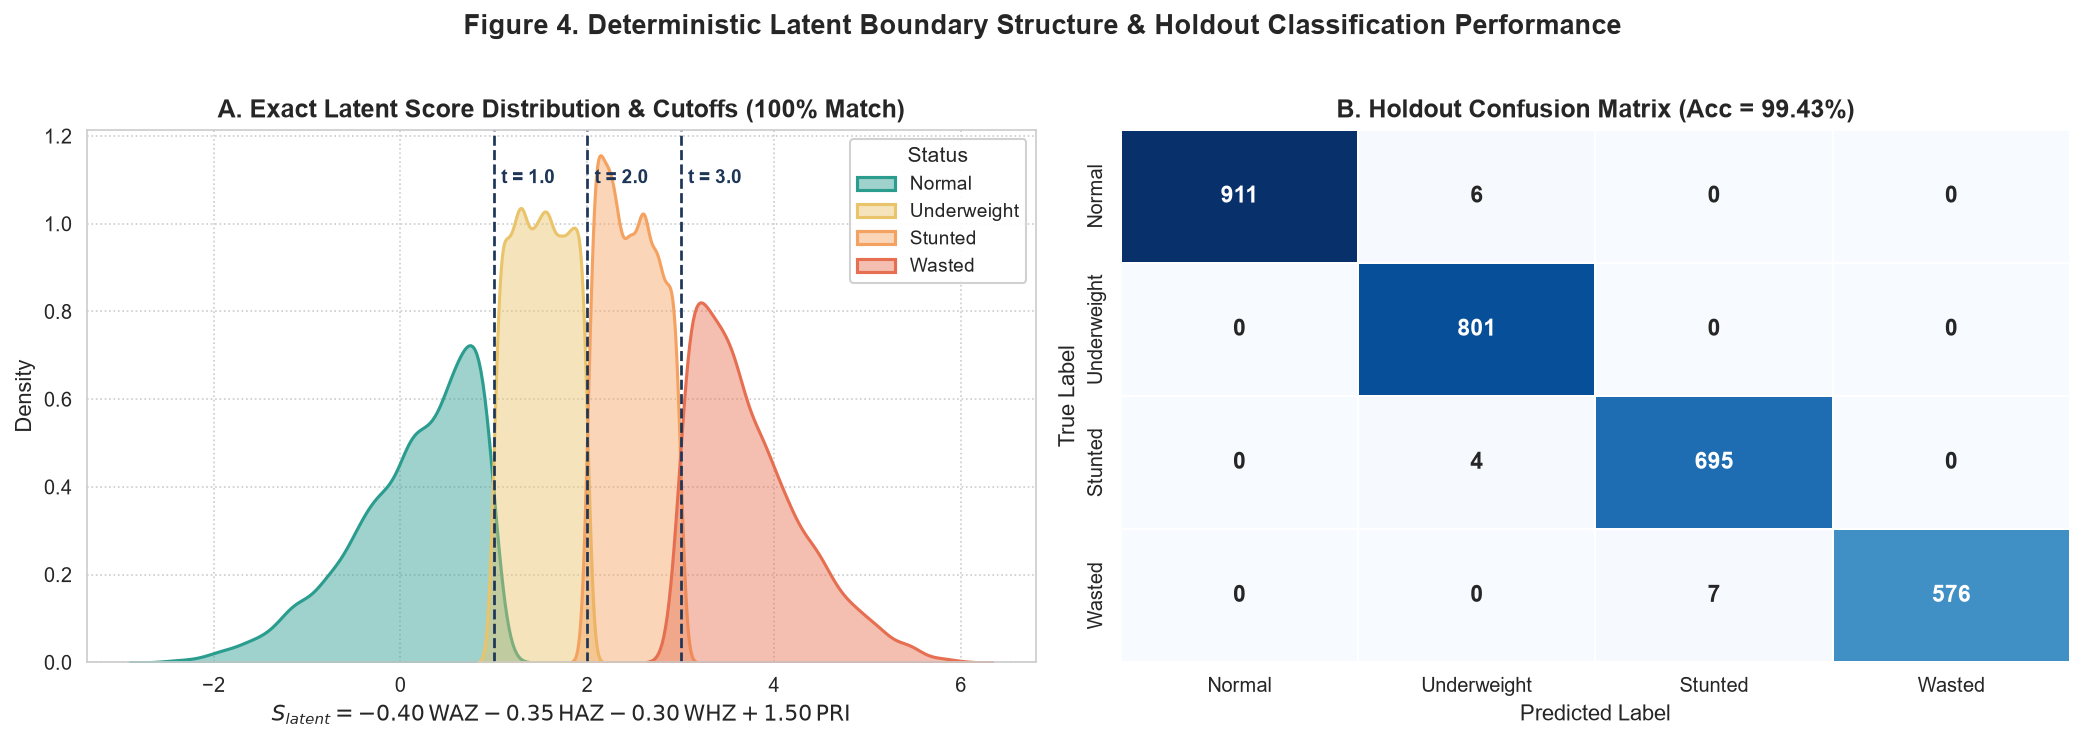

In [38]:
# Compute Exact Latent Score
df['Latent_Score'] = (
    -0.40 * df['Weight_for_Age_Z']
    - 0.35 * df['Height_for_Age_Z']
    - 0.30 * df['Weight_for_Height_Z']
    + 1.50 * df['Predictive_Risk_Index']
)

# Apply half-open thresholds [a, b)
df['Latent_Pred'] = pd.cut(
    df['Latent_Score'],
    bins=[-np.inf, 1.0, 2.0, 3.0, np.inf],
    labels=STATUS_ORDER,
    right=False
)

exact_matches = (df['Latent_Pred'] == df['Malnutrition_Status']).sum()
print(f"Exact Deterministic Formula Match: {exact_matches:,} / {len(df):,} ({exact_matches/len(df)*100:.4f}%)\n")

print("Latent Score Range by Malnutrition_Status:")
print(df.groupby('Malnutrition_Status')['Latent_Score'].agg(['count', 'min', 'max', 'mean', 'std']).loc[STATUS_ORDER].round(4).to_string())

# Figure 4: Latent Score Density + Holdout Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Panel A: Latent Score Density with Exact Cutoffs
for st in STATUS_ORDER:
    sns.kdeplot(df.loc[df['Malnutrition_Status'] == st, 'Latent_Score'],
                ax=axes[0], fill=True, alpha=0.45, linewidth=1.5, color=STATUS_PALETTE[st], label=st)
ylim_top = axes[0].get_ylim()[1]
for t in [1.0, 2.0, 3.0]:
    axes[0].axvline(t, color='#1D3557', linestyle='--', linewidth=1.3)
    axes[0].text(t + 0.08, ylim_top * 0.90, f"t = {t:.1f}", color='#1D3557', fontsize=9, fontweight='bold')
axes[0].set_title('A. Exact Latent Score Distribution & Cutoffs (100% Match)')
axes[0].set_xlabel('$S_{latent} = -0.40\,\mathrm{WAZ} - 0.35\,\mathrm{HAZ} - 0.30\,\mathrm{WHZ} + 1.50\,\mathrm{PRI}$')
axes[0].set_ylabel('Density')
axes[0].legend(title='Status')

# Panel B: Holdout Confusion Matrix (4-Feature Logistic Regression)
cm = confusion_matrix(y_test, y_pred, labels=STATUS_ORDER)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=STATUS_ORDER, yticklabels=STATUS_ORDER,
            cbar=False, linewidths=0.8, ax=axes[1], annot_kws={'size': 11, 'fontweight': 'bold'})
axes[1].set_title(f'B. Holdout Confusion Matrix (Acc = {accuracy_score(y_test, y_pred)*100:.2f}%)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.suptitle('Figure 4. Deterministic Latent Boundary Structure & Holdout Classification Performance',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'Fig4_Latent_Score_and_CM.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Proposed Clinical Malnutrition Risk Scoring System (0–100 Scale)

### 6.1 Methodological Motivation
While $S_{\text{latent}}$ perfectly reconstructs the dataset's synthetic labels, it is unsuitable for real-world clinical triage because it treats `Stunted` and `Wasted` as points along a single linear axis and ignores acute infectious morbidity, feeding practices, and household vulnerability.

We therefore formulate a transparent, domain-grounded **100-point Multi-Pillar Clinical Risk Score** aligned with WHO/UNICEF Child Growth Standards and Community-Based Management of Acute Malnutrition (CMAM) guidelines:

| Pillar | Weight | Component Indicators & Point Allocations |
| :--- | :---: | :--- |
| **1. Anthropometric Deficit** | **50 pts** | `WAZ` ($<-3$: 15, $[-3,-2)$: 10, $[-2,-1)$: 5); `HAZ` ($<-3$: 15, $[-3,-2)$: 10, $[-2,-1)$: 5); `WHZ` ($<-3$: 12, $[-3,-2)$: 8, $[-2,-1)$: 4); `MUAC` ($<11.5$ cm: 8, $[11.5, 12.5)$: 5) |
| **2. Clinical & Immunity** | **15 pts** | `Recent_Diarrhea` (Yes: 5); `Recent_Fever` (Yes: 4); `Immunization_Status` (None: 4, Partial: 2); `Vitamin_A_Supplement` (No: 2) |
| **3. Feeding & Maternal Care** | **15 pts** | `Exclusive_Breastfeeding` (No: 4); `Dietary_Diversity_Score` ($<4$: 4); `Meal_Frequency` ($<3$: 3); `ANC_Visits` ($<4$: 2); `Birth_Weight_kg` ($<2.5$: 2) |
| **4. Socioeconomic & WASH** | **20 pts** | `Food_Security_Status` (Insecure: 6, Moderate: 3); `Wealth_Index` (Low: 5, Medium: 2); `Drinking_Water_Source` (Unprotected: 3); `Sanitation_Facility` (Unimproved: 3); `Mother_Education` (None: 3, Primary: 1) |

### 6.2 Vectorized Implementation & Validation

In [39]:
def compute_clinical_risk_score(data: pd.DataFrame) -> pd.DataFrame:
    """Compute 4-pillar Clinical Malnutrition Risk Score (0-100) and Triage Tiers."""
    out = pd.DataFrame(index=data.index)

    def _score_z(series, sev, mod, mild):
        return np.where(series < -3, sev, np.where(series < -2, mod, np.where(series < -1, mild, 0)))

    # Pillar 1: Anthropometry (50 pts)
    out['Pillar_Anthropometry'] = (
        _score_z(data['Weight_for_Age_Z'], 15, 10, 5)
        + _score_z(data['Height_for_Age_Z'], 15, 10, 5)
        + _score_z(data['Weight_for_Height_Z'], 12, 8, 4)
        + np.where(data['MUAC_cm'] < 11.5, 8, np.where(data['MUAC_cm'] < 12.5, 5, 0))
    )

    # Pillar 2: Clinical & Immunity (15 pts)
    out['Pillar_Clinical'] = (
        np.where(data['Recent_Diarrhea'] == 'Yes', 5, 0)
        + np.where(data['Recent_Fever'] == 'Yes', 4, 0)
        + np.where(data['Immunization_Status'] == 'None', 4,
                   np.where(data['Immunization_Status'] == 'Partial', 2, 0))
        + np.where(data['Vitamin_A_Supplement'] == 'No', 2, 0)
    )

    # Pillar 3: IYCF Feeding & Maternal Care (15 pts)
    out['Pillar_Feeding'] = (
        np.where(data['Exclusive_Breastfeeding'] == 'No', 4, 0)
        + np.where(data['Dietary_Diversity_Score'] < 4, 4, 0)
        + np.where(data['Meal_Frequency'] < 3, 3, 0)
        + np.where(data['ANC_Visits'] < 4, 2, 0)
        + np.where(data['Birth_Weight_kg'] < 2.5, 2, 0)
    )

    # Pillar 4: Socioeconomic & WASH Vulnerability (20 pts)
    out['Pillar_SES_WASH'] = (
        np.where(data['Food_Security_Status'] == 'Insecure', 6,
                 np.where(data['Food_Security_Status'] == 'Moderate', 3, 0))
        + np.where(data['Wealth_Index'] == 'Low', 5,
                   np.where(data['Wealth_Index'] == 'Medium', 2, 0))
        + np.where(data['Drinking_Water_Source'] == 'Unprotected', 3, 0)
        + np.where(data['Sanitation_Facility'] == 'Unimproved', 3, 0)
        + np.where(data['Mother_Education'] == 'None', 3,
                   np.where(data['Mother_Education'] == 'Primary', 1, 0))
    )

    out['Clinical_Risk_Score'] = (
        out['Pillar_Anthropometry'] + out['Pillar_Clinical']
        + out['Pillar_Feeding'] + out['Pillar_SES_WASH']
    )

    out['Risk_Tier'] = pd.cut(
        out['Clinical_Risk_Score'],
        bins=[-1, 24, 44, 64, 100],
        labels=['Low (0-24)', 'Moderate (25-44)', 'High (45-64)', 'Critical (65-100)']
    )
    return out

scores_df = compute_clinical_risk_score(df)
df = pd.concat([df, scores_df], axis=1)

# Summary statistics & validation
rho, p_rho = stats.spearmanr(df['Clinical_Risk_Score'], df['Latent_Score'])
print("=== Clinical Risk Score (0-100) Validation ===")
print(f"Overall Mean ± SD: {df['Clinical_Risk_Score'].mean():.2f} ± {df['Clinical_Risk_Score'].std():.2f} "
      f"| Median (IQR): {df['Clinical_Risk_Score'].median():.1f} ({df['Clinical_Risk_Score'].quantile(0.25):.1f}–{df['Clinical_Risk_Score'].quantile(0.75):.1f}) "
      f"| Range: {df['Clinical_Risk_Score'].min()}–{df['Clinical_Risk_Score'].max()}")
print(f"Spearman Rank Correlation with Latent Severity: rho = {rho:.4f} (p < 1e-300)\n")

tier_summary = pd.DataFrame({
    'Count': df['Risk_Tier'].value_counts().sort_index(),
    'Percent (%)': (df['Risk_Tier'].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Risk Tier Stratification:")
print(tier_summary.to_string())

print("\nMean Clinical Risk Score by Malnutrition_Status:")
print(df.groupby('Malnutrition_Status')['Clinical_Risk_Score'].agg(['mean', 'std', 'median']).loc[STATUS_ORDER].round(2).to_string())

=== Clinical Risk Score (0-100) Validation ===
Overall Mean ± SD: 33.47 ± 12.00 | Median (IQR): 33.0 (25.0–42.0) | Range: 1–78
Spearman Rank Correlation with Latent Severity: rho = 0.7203 (p < 1e-300)

Risk Tier Stratification:
                   Count  Percent (%)
Risk_Tier                            
Low (0-24)          3646        24.31
Moderate (25-44)    8605        57.37
High (45-64)        2659        17.73
Critical (65-100)     90         0.60

Mean Clinical Risk Score by Malnutrition_Status:
                      mean   std  median
Malnutrition_Status                     
Normal               23.72  8.49    23.0
Underweight          31.21  8.53    31.0
Stunted              37.72  8.67    38.0
Wasted               46.77  9.09    46.5


### 6.3 Clinical Risk Score Stratification & Pillar Decomposition (Figure 5)
Figure 5 displays the full risk score distribution across triage tiers, its monotonic separation by `Malnutrition_Status`, and the mean point contribution of each of the four pillars within each risk tier.

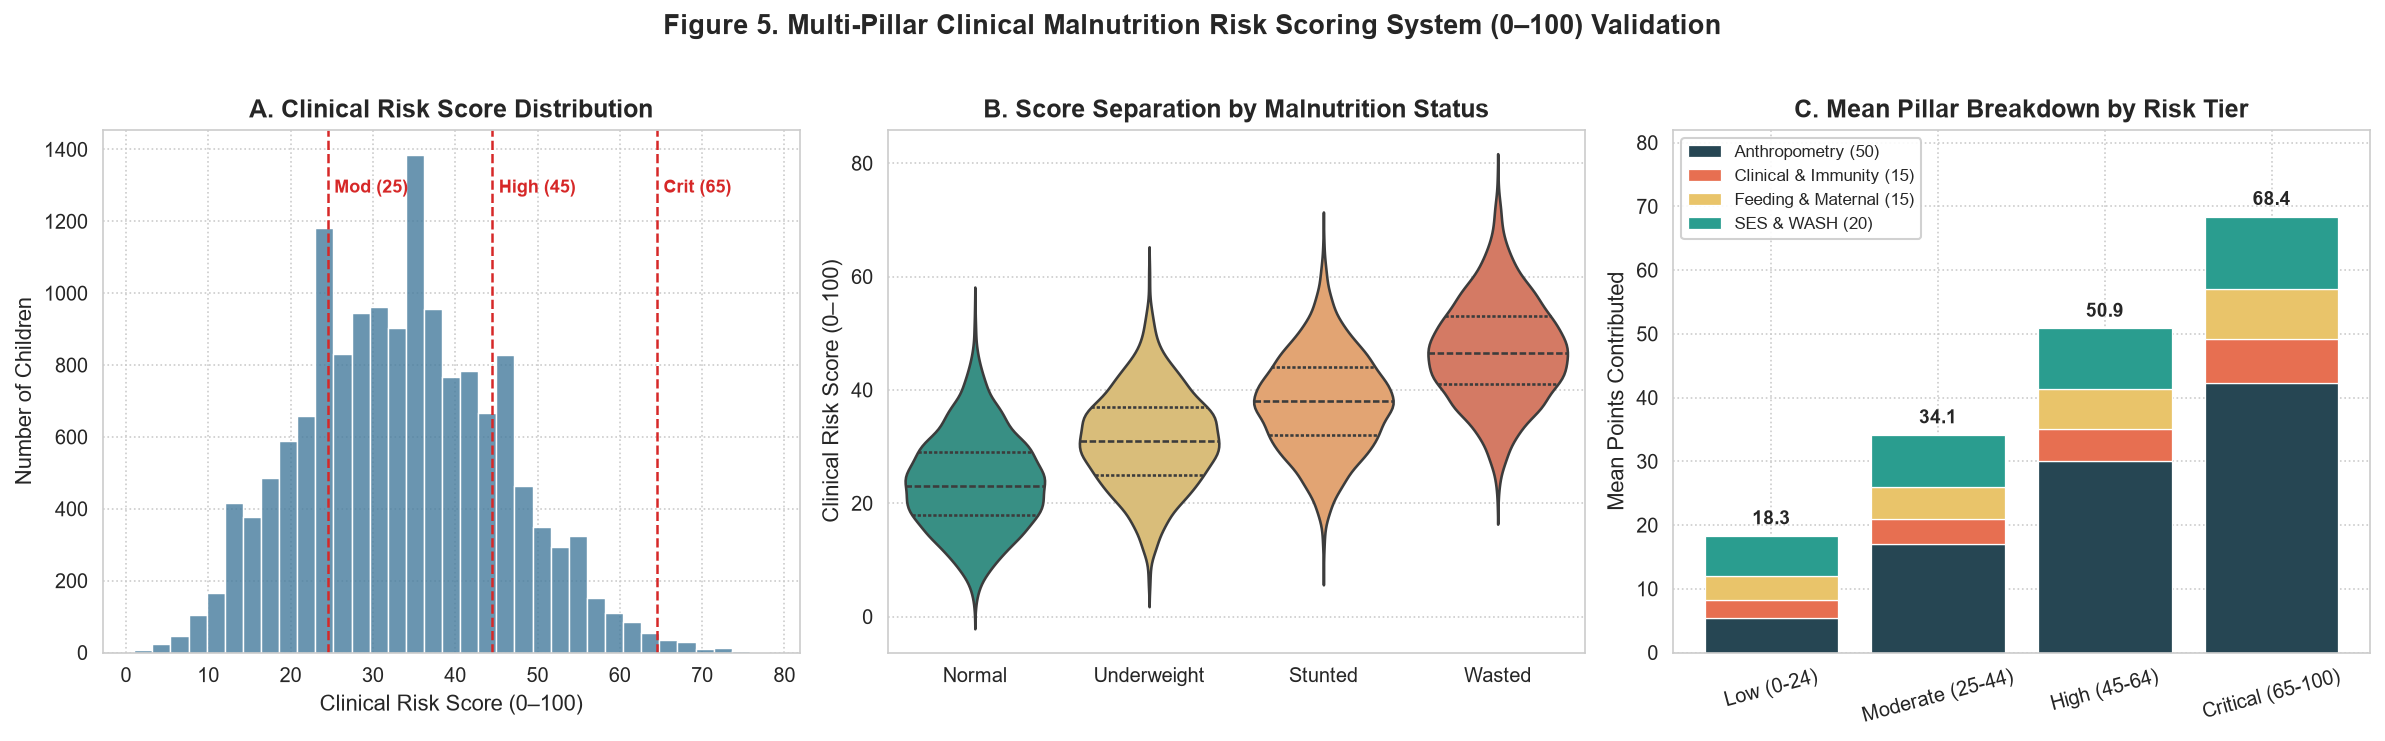

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
TIER_ORDER = ['Low (0-24)', 'Moderate (25-44)', 'High (45-64)', 'Critical (65-100)']

# Panel A: Risk Score Histogram with Tier Boundaries
sns.histplot(df['Clinical_Risk_Score'], bins=35, color='#457B9D', edgecolor='white', alpha=0.8, ax=axes[0])
ylim_a = axes[0].get_ylim()[1]
for cutoff, lbl in [(24.5, 'Mod (25)'), (44.5, 'High (45)'), (64.5, 'Crit (65)')]:
    axes[0].axvline(cutoff, color='#D62828', linestyle='--', linewidth=1.2)
    axes[0].text(cutoff + 0.8, ylim_a * 0.88, lbl, color='#D62828', fontsize=8.5, fontweight='bold')
axes[0].set_title('A. Clinical Risk Score Distribution')
axes[0].set_xlabel('Clinical Risk Score (0–100)')
axes[0].set_ylabel('Number of Children')

# Panel B: Violin Plot by Malnutrition Status
sns.violinplot(data=df, x='Malnutrition_Status', y='Clinical_Risk_Score', order=STATUS_ORDER,
               palette=STATUS_PALETTE, inner='quartile', ax=axes[1])
axes[1].set_title('B. Score Separation by Malnutrition Status')
axes[1].set_xlabel('')
axes[1].set_ylabel('Clinical Risk Score (0–100)')

# Panel C: Stacked Bar Chart of Mean Pillar Contributions by Risk Tier
pillar_cols = ['Pillar_Anthropometry', 'Pillar_Clinical', 'Pillar_Feeding', 'Pillar_SES_WASH']
pillar_labels = ['Anthropometry (50)', 'Clinical & Immunity (15)', 'Feeding & Maternal (15)', 'SES & WASH (20)']
pillar_colors = ['#264653', '#E76F51', '#E9C46A', '#2A9D8F']

tier_means = df.groupby('Risk_Tier', observed=False)[pillar_cols].mean().reindex(TIER_ORDER)
bottom = np.zeros(len(TIER_ORDER))
for col, lbl, clr in zip(pillar_cols, pillar_labels, pillar_colors):
    vals = tier_means[col].values
    axes[2].bar(TIER_ORDER, vals, bottom=bottom, label=lbl, color=clr, edgecolor='white', linewidth=0.6)
    bottom += vals
for i, total in enumerate(bottom):
    axes[2].text(i, total + 1.2, f"{total:.1f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

axes[2].set_title('C. Mean Pillar Breakdown by Risk Tier')
axes[2].set_ylabel('Mean Points Contributed')
axes[2].set_ylim(0, 82)
axes[2].tick_params(axis='x', rotation=15)
axes[2].legend(loc='upper left', fontsize=8)

plt.suptitle('Figure 5. Multi-Pillar Clinical Malnutrition Risk Scoring System (0–100) Validation',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'Fig5_Clinical_Risk_Scoring.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.4 Publication Infographic: Multi-Pillar Clinical Malnutrition Risk Scoring System (Figure 6)
Figure 6 synthesizes the complete **0–100 Clinical Malnutrition Risk Scoring System** into a standalone, publication-ready visual infographic detailing the pillar weight architecture, indicator-level scoring rules, proportional triage tier prevalence across all 15,000 children, and recommended clinical intervention protocols.

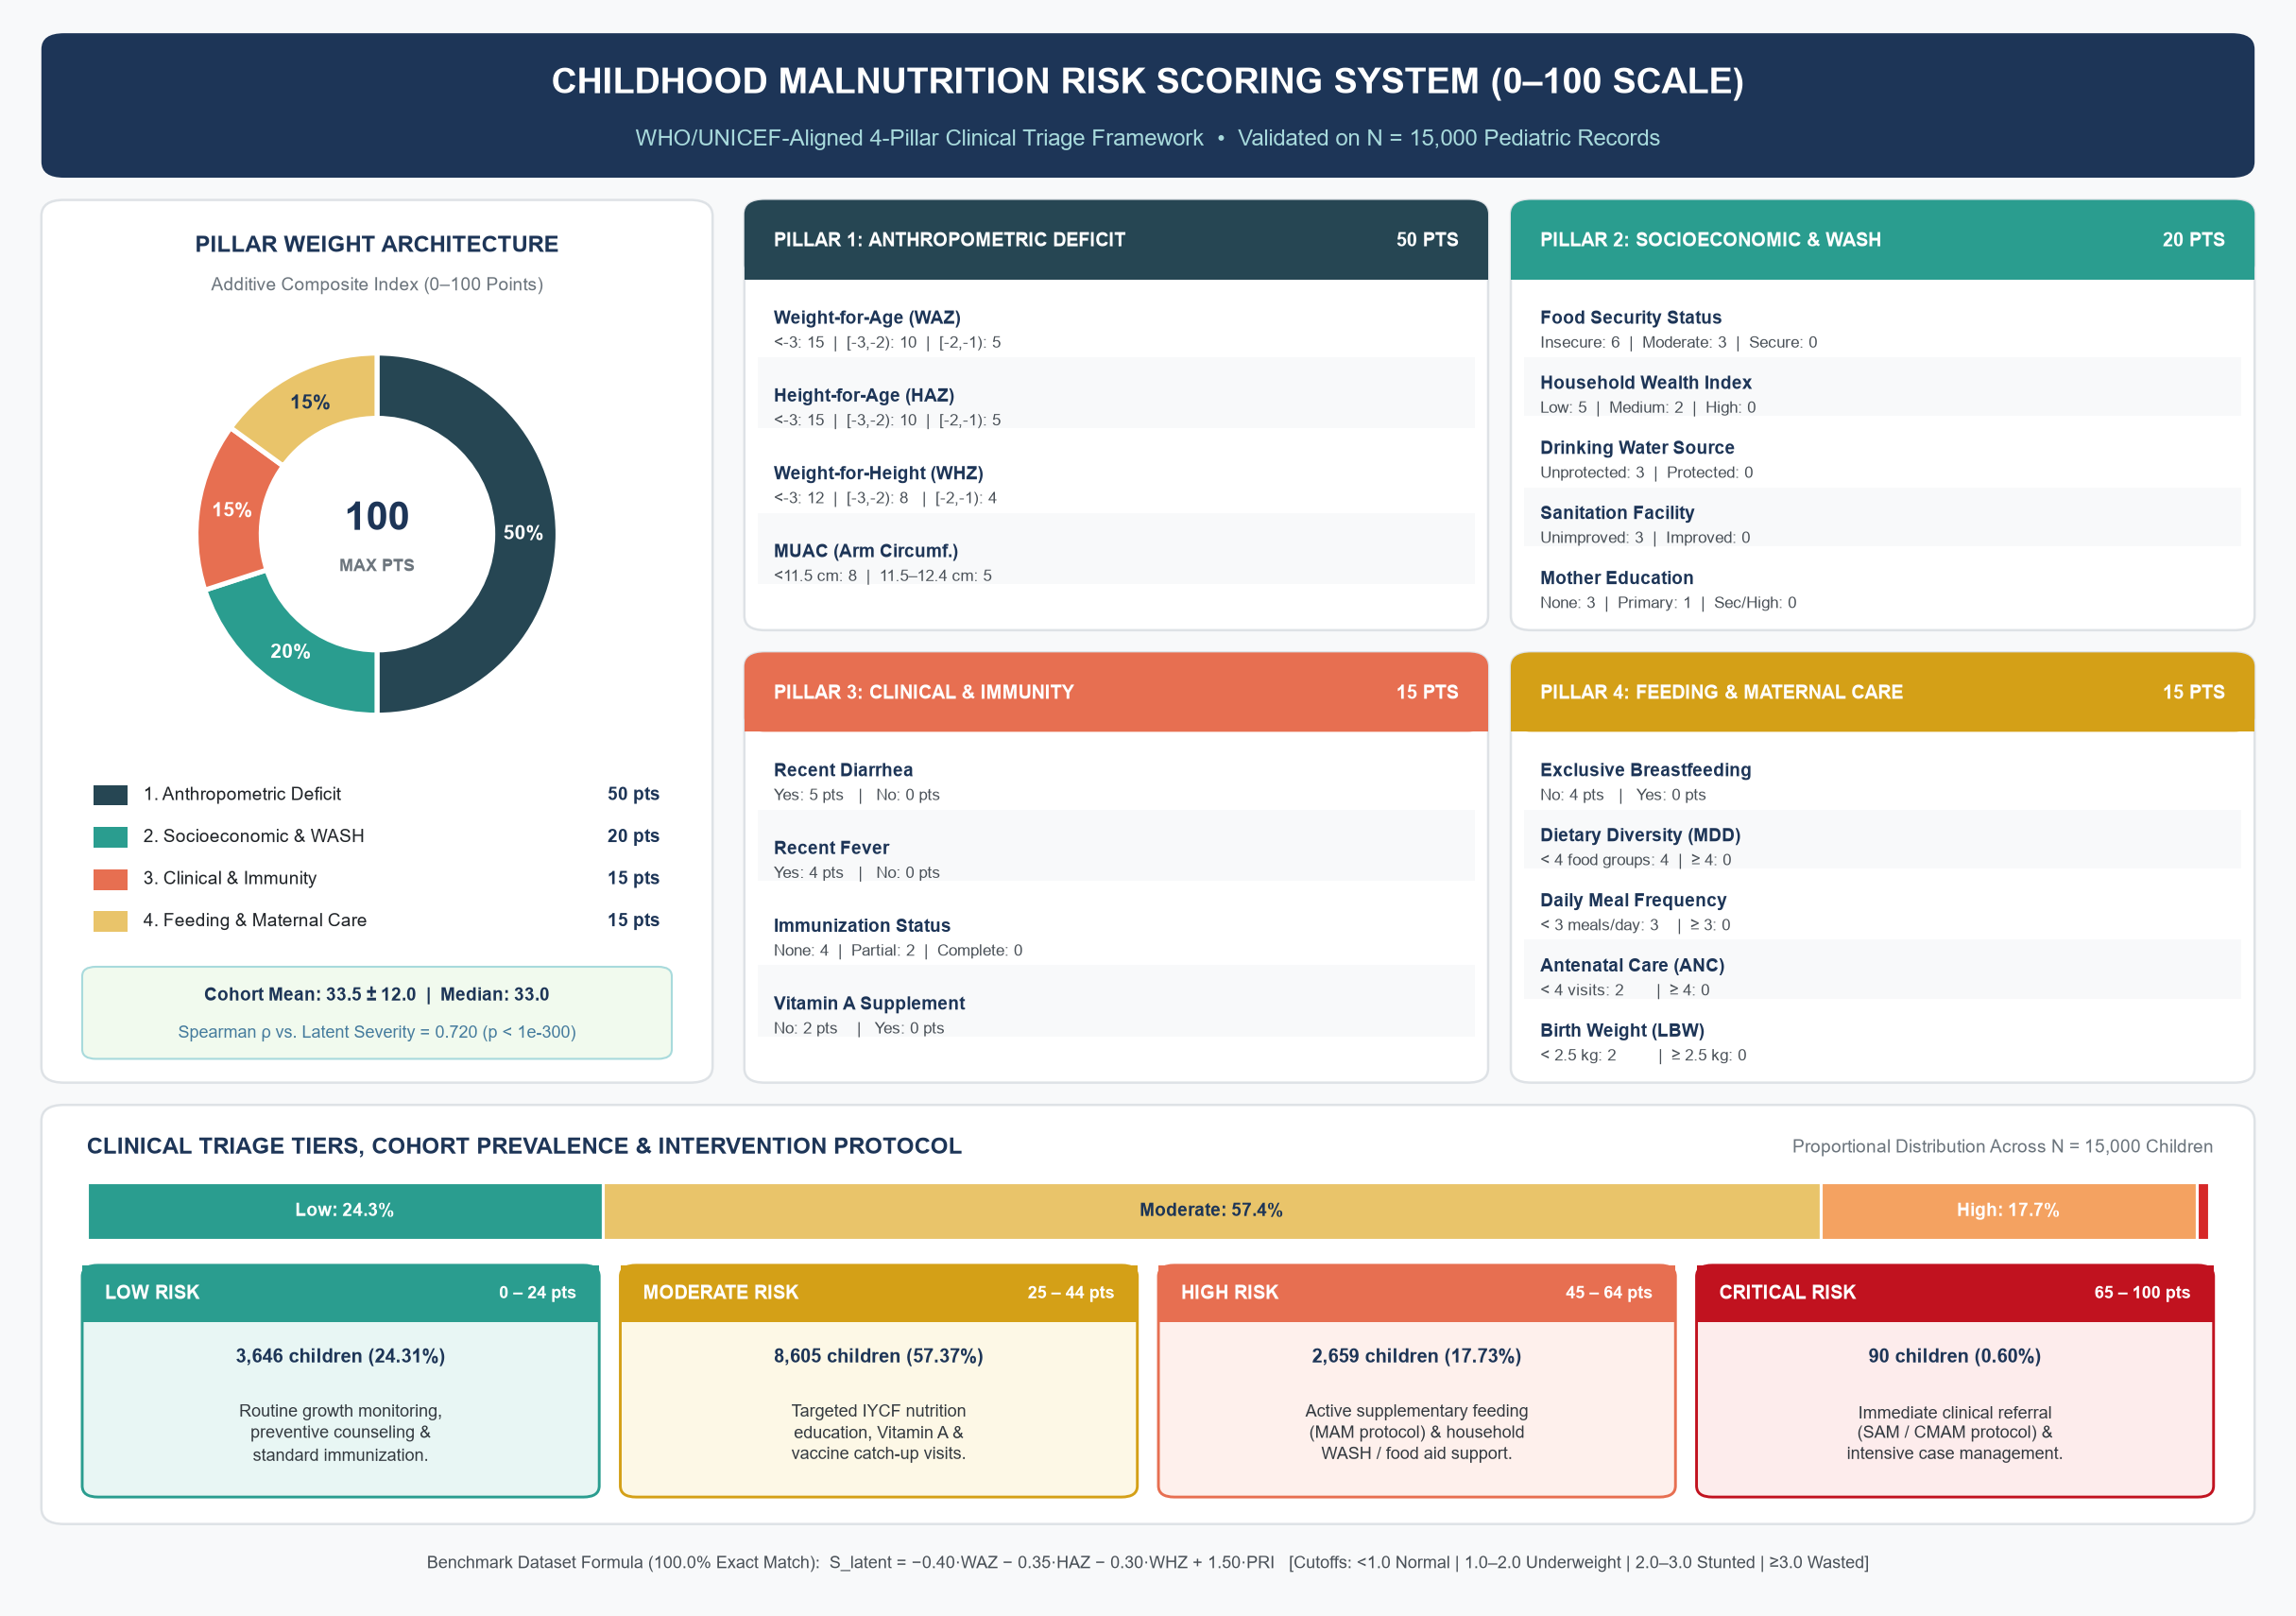

In [41]:
import matplotlib.patches as patches

def build_scoring_infographic(df_in, save_path='Fig6_Scoring_System_Infographic.png'):
    """Build a publication-ready 300-DPI infographic of the 0-100 Clinical Risk Scoring System."""
    N_tot = len(df_in)
    m_sc = df_in['Clinical_Risk_Score'].mean()
    s_sc = df_in['Clinical_Risk_Score'].std()
    md_sc = df_in['Clinical_Risk_Score'].median()
    sp_rho, _ = stats.spearmanr(df_in['Clinical_Risk_Score'], df_in['Latent_Score'])
    t_order = ['Low (0-24)', 'Moderate (25-44)', 'High (45-64)', 'Critical (65-100)']
    t_counts = df_in['Risk_Tier'].value_counts().reindex(t_order)
    t_pcts = t_counts / N_tot * 100

    fig = plt.figure(figsize=(16, 11.2), facecolor='#F8F9FA')
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis('off')
    ax.set_facecolor('#F8F9FA')

    # 1. HEADER BANNER
    header = patches.FancyBboxPatch(
        (1.5, 90.0), 97.0, 8.5,
        boxstyle='round,pad=0.3,rounding_size=1.0',
        facecolor='#1D3557', edgecolor='none'
    )
    ax.add_patch(header)
    ax.text(50, 95.6, 'CHILDHOOD MALNUTRITION RISK SCORING SYSTEM (0–100 SCALE)',
            ha='center', va='center', color='white', fontsize=18, fontweight='bold')
    ax.text(50, 92.1, f'WHO/UNICEF-Aligned 4-Pillar Clinical Triage Framework  •  Validated on N = {N_tot:,} Pediatric Records',
            ha='center', va='center', color='#A8DADC', fontsize=11.5, fontweight='medium')

    # 2. LEFT PANEL: PILLAR WEIGHT DONUT + COHORT KPI SUMMARY
    left_card = patches.FancyBboxPatch(
        (1.5, 33.0), 29.0, 55.0,
        boxstyle='round,pad=0.3,rounding_size=1.0',
        facecolor='white', edgecolor='#DEE2E6', linewidth=1.2
    )
    ax.add_patch(left_card)
    ax.text(16.0, 85.4, 'PILLAR WEIGHT ARCHITECTURE',
            ha='center', va='center', color='#1D3557', fontsize=11.5, fontweight='bold')
    ax.text(16.0, 82.9, 'Additive Composite Index (0–100 Points)',
            ha='center', va='center', color='#6C757D', fontsize=9.2)

    # Embedded Donut Chart Axis (positioned cleanly above legend)
    ax_donut = fig.add_axes([0.035, 0.530, 0.25, 0.285])
    weights = [50, 20, 15, 15]
    p_colors = ['#264653', '#2A9D8F', '#E76F51', '#E9C46A']
    wedges, _ = ax_donut.pie(
        weights, colors=p_colors, startangle=90, counterclock=False,
        wedgeprops=dict(width=0.36, edgecolor='white', linewidth=2.5)
    )
    for w, val in zip(wedges, weights):
        ang = np.deg2rad((w.theta2 + w.theta1) / 2.0)
        x_t = 0.81 * np.cos(ang)
        y_t = 0.81 * np.sin(ang)
        txt_clr = '#1D3557' if w == wedges[-1] else 'white'
        ax_donut.text(x_t, y_t, f'{val}%', ha='center', va='center',
                      color=txt_clr, fontsize=10, fontweight='bold')
    ax_donut.text(0, 0.08, '100', ha='center', va='center', color='#1D3557', fontsize=20, fontweight='bold')
    ax_donut.text(0, -0.18, 'MAX PTS', ha='center', va='center', color='#6C757D', fontsize=8.5, fontweight='bold')
    ax_donut.set_aspect('equal')

    # Legend under donut (well-spaced above KPI box)
    leg_items = [
        ('#264653', '1. Anthropometric Deficit', '50 pts'),
        ('#2A9D8F', '2. Socioeconomic & WASH', '20 pts'),
        ('#E76F51', '3. Clinical & Immunity', '15 pts'),
        ('#E9C46A', '4. Feeding & Maternal Care', '15 pts'),
    ]
    y_leg = 50.8
    for clr, name, pts in leg_items:
        ax.add_patch(patches.Rectangle((3.5, y_leg - 0.65), 1.5, 1.3, facecolor=clr, edgecolor='none'))
        ax.text(5.7, y_leg, name, ha='left', va='center', color='#212529', fontsize=9.2, fontweight='medium')
        ax.text(28.5, y_leg, pts, ha='right', va='center', color='#1D3557', fontsize=9.2, fontweight='bold')
        y_leg -= 2.65

    # Cohort Validation Mini-Box
    kpi_box = patches.FancyBboxPatch(
        (3.2, 34.4), 25.6, 5.4,
        boxstyle='round,pad=0.2,rounding_size=0.6',
        facecolor='#F1FAEE', edgecolor='#A8DADC', linewidth=1.0
    )
    ax.add_patch(kpi_box)
    ax.text(16.0, 38.2, f'Cohort Mean: {m_sc:.1f} ± {s_sc:.1f}  |  Median: {md_sc:.1f}',
            ha='center', va='center', color='#1D3557', fontsize=9.2, fontweight='bold')
    ax.text(16.0, 35.8, f'Spearman ρ vs. Latent Severity = {sp_rho:.3f} (p < 1e-300)',
            ha='center', va='center', color='#457B9D', fontsize=8.6, fontweight='medium')

    # 3. RIGHT PANEL: 4 PILLAR RUBRIC CARDS (2x2 GRID)
    cards_data = [
        {
            'x': 32.5, 'y': 61.5, 'w': 32.2, 'h': 26.5,
            'color': '#264653', 'title': 'PILLAR 1: ANTHROPOMETRIC DEFICIT', 'pts': '50 PTS',
            'rows': [
                ('Weight-for-Age (WAZ)', '<-3: 15  |  [-3,-2): 10  |  [-2,-1): 5'),
                ('Height-for-Age (HAZ)', '<-3: 15  |  [-3,-2): 10  |  [-2,-1): 5'),
                ('Weight-for-Height (WHZ)', '<-3: 12  |  [-3,-2): 8   |  [-2,-1): 4'),
                ('MUAC (Arm Circumf.)', '<11.5 cm: 8  |  11.5–12.4 cm: 5'),
            ]
        },
        {
            'x': 66.3, 'y': 61.5, 'w': 32.2, 'h': 26.5,
            'color': '#2A9D8F', 'title': 'PILLAR 2: SOCIOECONOMIC & WASH', 'pts': '20 PTS',
            'rows': [
                ('Food Security Status', 'Insecure: 6  |  Moderate: 3  |  Secure: 0'),
                ('Household Wealth Index', 'Low: 5  |  Medium: 2  |  High: 0'),
                ('Drinking Water Source', 'Unprotected: 3  |  Protected: 0'),
                ('Sanitation Facility', 'Unimproved: 3  |  Improved: 0'),
                ('Mother Education', 'None: 3  |  Primary: 1  |  Sec/High: 0'),
            ]
        },
        {
            'x': 32.5, 'y': 33.0, 'w': 32.2, 'h': 26.5,
            'color': '#E76F51', 'title': 'PILLAR 3: CLINICAL & IMMUNITY', 'pts': '15 PTS',
            'rows': [
                ('Recent Diarrhea', 'Yes: 5 pts   |   No: 0 pts'),
                ('Recent Fever', 'Yes: 4 pts   |   No: 0 pts'),
                ('Immunization Status', 'None: 4  |  Partial: 2  |  Complete: 0'),
                ('Vitamin A Supplement', 'No: 2 pts    |   Yes: 0 pts'),
            ]
        },
        {
            'x': 66.3, 'y': 33.0, 'w': 32.2, 'h': 26.5,
            'color': '#D4A017', 'title': 'PILLAR 4: FEEDING & MATERNAL CARE', 'pts': '15 PTS',
            'rows': [
                ('Exclusive Breastfeeding', 'No: 4 pts   |   Yes: 0 pts'),
                ('Dietary Diversity (MDD)', '< 4 food groups: 4  |  ≥ 4: 0'),
                ('Daily Meal Frequency', '< 3 meals/day: 3    |  ≥ 3: 0'),
                ('Antenatal Care (ANC)', '< 4 visits: 2       |  ≥ 4: 0'),
                ('Birth Weight (LBW)', '< 2.5 kg: 2         |  ≥ 2.5 kg: 0'),
            ]
        },
    ]

    for cd in cards_data:
        x0, y0, w, h = cd['x'], cd['y'], cd['w'], cd['h']
        ax.add_patch(patches.FancyBboxPatch(
            (x0, y0), w, h,
            boxstyle='round,pad=0.3,rounding_size=0.9',
            facecolor='white', edgecolor='#DEE2E6', linewidth=1.2
        ))
        ax.add_patch(patches.FancyBboxPatch(
            (x0, y0 + h - 4.4), w, 4.4,
            boxstyle='round,pad=0.3,rounding_size=0.9',
            facecolor=cd['color'], edgecolor='none'
        ))
        ax.add_patch(patches.Rectangle((x0 - 0.3, y0 + h - 4.7), w + 0.6, 1.5, facecolor=cd['color'], edgecolor='none'))
        ax.text(x0 + 1.0, y0 + h - 2.3, cd['title'], ha='left', va='center',
                color='white', fontsize=9.8, fontweight='bold')
        ax.text(x0 + w - 1.0, y0 + h - 2.3, cd['pts'], ha='right', va='center',
                color='white', fontsize=9.8, fontweight='bold')

        n_rows = len(cd['rows'])
        top_row_y = y0 + h - 7.6
        row_step = 4.1 if n_rows == 5 else 4.9
        for i, (ind, rule) in enumerate(cd['rows']):
            ry = top_row_y - i * row_step
            if i % 2 == 1:
                ax.add_patch(patches.Rectangle((x0 + 0.3, ry - 1.6), w - 0.6, row_step - 0.4,
                                               facecolor='#F8F9FA', edgecolor='none'))
            ax.text(x0 + 1.0, ry + 0.4, ind, ha='left', va='center',
                    color='#1D3557', fontsize=8.9, fontweight='bold')
            ax.text(x0 + 1.0, ry - 1.15, rule, ha='left', va='center',
                    color='#495057', fontsize=8.2)

    # 4. BOTTOM PANEL: CLINICAL TRIAGE TIERS & ACTION PROTOCOL
    bot_card = patches.FancyBboxPatch(
        (1.5, 5.2), 97.0, 25.8,
        boxstyle='round,pad=0.3,rounding_size=1.0',
        facecolor='white', edgecolor='#DEE2E6', linewidth=1.2
    )
    ax.add_patch(bot_card)
    ax.text(3.2, 28.6, 'CLINICAL TRIAGE TIERS, COHORT PREVALENCE & INTERVENTION PROTOCOL',
            ha='left', va='center', color='#1D3557', fontsize=11.5, fontweight='bold')
    ax.text(97.0, 28.6, f'Proportional Distribution Across N = {N_tot:,} Children',
            ha='right', va='center', color='#6C757D', fontsize=9.2)

    # Proportional Horizontal Stacked Bar
    bar_x, bar_w, bar_y, bar_h = 3.2, 93.6, 22.8, 3.6
    tier_colors = ['#2A9D8F', '#E9C46A', '#F4A261', '#D62828']
    cur_x = bar_x
    for lbl, cnt, pct, clr in zip(t_order, t_counts.values, t_pcts.values, tier_colors):
        seg_w = bar_w * (pct / 100.0)
        ax.add_patch(patches.Rectangle((cur_x, bar_y), seg_w, bar_h, facecolor=clr, edgecolor='white', linewidth=1.5))
        if pct >= 10:
            t_clr = '#1D3557' if clr == '#E9C46A' else 'white'
            ax.text(cur_x + seg_w / 2.0, bar_y + bar_h / 2.0, f'{lbl.split()[0]}: {pct:.1f}%',
                    ha='center', va='center', color=t_clr, fontsize=9.2, fontweight='bold')
        cur_x += seg_w

    # 4 Tier Action Cards
    tier_specs = [
        ('LOW RISK', '0 – 24 pts', '#2A9D8F', '#E8F6F4',
         'Routine growth monitoring,\npreventive counseling &\nstandard immunization.'),
        ('MODERATE RISK', '25 – 44 pts', '#D4A017', '#FDF8E6',
         'Targeted IYCF nutrition\neducation, Vitamin A &\nvaccine catch-up visits.'),
        ('HIGH RISK', '45 – 64 pts', '#E76F51', '#FEF0EC',
         'Active supplementary feeding\n(MAM protocol) & household\nWASH / food aid support.'),
        ('CRITICAL RISK', '65 – 100 pts', '#C1121F', '#FDECEC',
         'Immediate clinical referral\n(SAM / CMAM protocol) &\nintensive case management.'),
    ]
    card_w, gap, start_x = 22.4, 1.33, 3.2
    for i, ((t_name, rng, clr, bg, action), cnt, pct) in enumerate(zip(tier_specs, t_counts.values, t_pcts.values)):
        cx = start_x + i * (card_w + gap)
        ax.add_patch(patches.FancyBboxPatch(
            (cx, 6.8), card_w, 14.2,
            boxstyle='round,pad=0.2,rounding_size=0.7',
            facecolor=bg, edgecolor=clr, linewidth=1.4
        ))
        ax.add_patch(patches.Rectangle((cx - 0.2, 17.6), card_w + 0.4, 3.6, facecolor=clr, edgecolor='none'))
        ax.text(cx + 0.8, 19.4, t_name, ha='left', va='center', color='white', fontsize=9.6, fontweight='bold')
        ax.text(cx + card_w - 0.8, 19.4, rng, ha='right', va='center', color='white', fontsize=8.8, fontweight='bold')
        ax.text(cx + card_w / 2.0, 15.4, f'{cnt:,} children ({pct:.2f}%)',
                ha='center', va='center', color='#1D3557', fontsize=9.5, fontweight='bold')
        ax.text(cx + card_w / 2.0, 10.6, action, ha='center', va='center',
                color='#343A40', fontsize=8.5, linespacing=1.35)

    # 5. FOOTER REFERENCE BAR
    ax.text(50, 2.4,
            'Benchmark Dataset Formula (100.0% Exact Match):  S_latent = −0.40·WAZ − 0.35·HAZ − 0.30·WHZ + 1.50·PRI   [Cutoffs: <1.0 Normal | 1.0–2.0 Underweight | 2.0–3.0 Stunted | ≥3.0 Wasted]',
            ha='center', va='center', color='#495057', fontsize=8.8, fontweight='medium')

    plt.savefig(OUTPUT_DIR / save_path, dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

build_scoring_infographic(df)

## 7. Export Enriched Dataset & Reproducibility Statement

Finally, we export the enriched dataset (`Childhood_Malnutrition_Scored.csv`) containing both the reverse-engineered `Latent_Score` and the 4-pillar `Clinical_Risk_Score` & `Risk_Tier` assignments, and log exact package versions for manuscript reproducibility.

In [42]:
import sys, scipy, statsmodels, sklearn

OUTPUT_CSV = DATA_DIR / "Childhood_Malnutrition_Scored.csv"
df.to_csv(OUTPUT_CSV, index=False)
print(f"Exported scored dataset: {OUTPUT_CSV} ({df.shape[0]:,} rows x {df.shape[1]} columns)")

print("\n=== Software & Package Versions (Reproducibility Log) ===")
print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"Statsmodels  : {statsmodels.__version__}")
print(f"Scikit-Learn : {sklearn.__version__}")
print(f"Matplotlib   : {plt.matplotlib.__version__}")
print(f"Seaborn      : {sns.__version__}")

Exported scored dataset: C:\Users\Thana\Projects\ChildhoodMalnutritionHealth\data\Childhood_Malnutrition_Scored.csv (15,000 rows x 48 columns)

=== Software & Package Versions (Reproducibility Log) ===
Python       : 3.13.14
NumPy        : 2.5.5
Pandas       : 3.1.1
SciPy        : 1.18.1
Statsmodels  : 0.15.0
Scikit-Learn : 1.9.1
Matplotlib   : 3.11.2
Seaborn      : 0.13.2
